DB_W01050
GLoD 1 - Median nMAE: 51.3977 lx, STD: 35.6025 lx
DB_W01050
GLoD 2 - Median nMAE: 41.8162 lx, STD: 34.3805 lx
DB_W01050
GLoD 3 - Median nMAE: 41.3027 lx, STD: 34.5567 lx


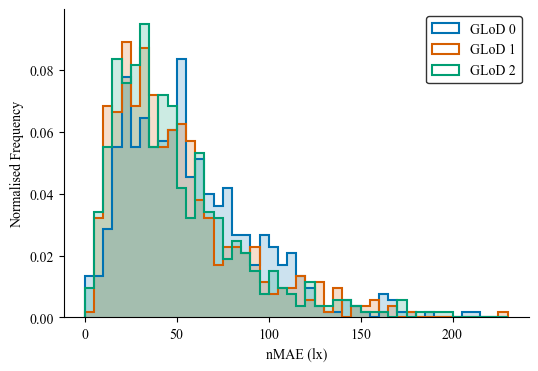

In [8]:
results = {
# "DB_550_LoD_1_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_1_actual_cubic.csv.gz",
# "DB_W01050_LoD_1_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_1_actual_cubic.csv.gz",
#"DB_550_LoD_1_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_1_actual_workplane.csv.gz",
"DB_W01050_LoD_1_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_1_actual_workplane.csv.gz",
# "DB_550_LoD_1_bounding_box_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_1_bounding_box_cubic.csv.gz",
# "DB_W01050_LoD_1_bounding_box_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_1_bounding_box_cubic.csv.gz",
# "DB_550_LoD_1_bounding_box_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_1_bounding_box_workplane.csv.gz", 
# "DB_W01050_LoD_1_bounding_box_workplane" :  r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_1_bounding_box_workplane.csv.gz", 
# "DB_550_LoD_2_actual_cubic" : r"/scratch/nforou
#zandehsh/temp/RQ1/DB_550_LoD_2_actual_cubic.csv.gz",
# "DB_W01050_LoD_2_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_2_actual_cubic.csv.gz",
#"DB_550_LoD_2_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_2_actual_workplane.csv.gz",
 "DB_W01050_LoD_2_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_2_actual_workplane.csv.gz",
# "DB_550_LoD_2_bounding_box_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_2_bounding_box_cubic.csv.gz",
# "DB_W01050_LoD_2_bounding_box_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_2_bounding_box_cubic.csv.gz",
# "DB_550_LoD_2_bounding_box_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_2_bounding_box_workplane.csv.gz",
# "DB_W01050_LoD_2_bounding_box_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_2_bounding_box_workplane.csv.gz",
# "DB_W01050_LoD_3_bounding_box_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_3_bounding_box_workplane.csv.gz",
# "DB_550_LoD_3_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_3_actual_workplane.csv.gz",
"DB_W01050_LoD_3_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_3_actual_workplane.csv.gz",
# "DB_550_LoD_4_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_4_actual_cubic.csv.gz",
# "DB_W01050_LoD_4_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_4_actual_cubic.csv.gz",
# "DB_550_LoD_4_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_4_actual_workplane.csv.gz",
"DB_W01050_LoD_4_actual_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_4_actual_workplane.csv.gz",
# "DB_550_LoD_4_bounding_box_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_4_bounding_box_cubic.csv.gz",
# "DB_W01050_LoD_4_bounding_box_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_4_bounding_box_cubic.csv.gz",
# "DB_550_LoD_4_bounding_box_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_4_bounding_box_workplane.csv.gz",
# "DB_W01050_LoD_4_bounding_box_workplane" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_4_bounding_box_workplane.csv.gz"
}



'''
DB_W01050_LoD_1_actual_workplane.csv.gz
DB_W01050_LoD_2_actual_workplane.csv.gz
DB_W01050_LoD_3_actual_workplane.csv.gz
DB_W01050_LoD_4_actual_workplane.csv.gz

=======================================================================================================================
Load these four, plot the dimension, 
for GLOD 1-3, calculate nRMSE as follows: sqrt(sigma1-H(E0-E3)^2/E3), it should be an array with the same size
as second dimension of the dataframe (grid points) per each GloD.

'''
import os 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def nrmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2)) / (np.max(y_true) - np.min(y_true))
dfs = {}

for room in [
    # "DB_550", 
    "DB_W01050"
    ]:
    for key, path in results.items():
        if "actual_workplane" in key:
            dfs[key] = pd.read_csv(path, compression='gzip')
        # calculate nMAE for GLoD 1-3 against GLoD 4

    for lod in [1, 2, 3]:
        lod_key = f"{room}_LoD_{lod}_actual_workplane"
        lod4_key = f"{room}_LoD_4_actual_workplane"
        y_true = dfs[lod4_key].iloc[:, 0:].values
        y_pred = dfs[lod_key].iloc[:, 0:].values
        nMAE_values = np.mean(np.abs(y_pred - y_true), axis=0) # nMAE_eup = np.mean(np.abs(eup_low - eup_gt), axis=1)
        dfs[f"nMAE_{lod_key}"] = pd.DataFrame(nMAE_values, columns=[f"nMAE_LoD_{lod}"])

    fig, ax = plt.subplots(figsize=(6, 4))
    # font to times
    plt.rcParams['font.family'] = 'Times New Roman'

    # shared bin edges across all three LoDs
    cols = [f"nMAE_LoD_{i}" for i in (1, 2, 3)]
    max_vals = []
    for df in dfs.values():
        if isinstance(df, pd.DataFrame):
            for c in cols:
                if c in df.columns:
                    max_vals.append(df[c].max())
    max_val = max(max_vals) if max_vals else 0
    bin_edges = np.arange(0, max_val + 5, 5)
    # colourblind-friendly Okabe–Ito palette
    colors = ["#0072B2", "#D55E00", "#009E73"]
    fill_alpha = 0.2

    for lod, color in zip([1, 2, 3], colors):
        nmae_key = f"nMAE_{room}_LoD_{lod}_actual_workplane"
        if nmae_key not in dfs:
            continue

        col = f"nMAE_LoD_{lod}"
        values = dfs[nmae_key][col].dropna().values
        if len(values) == 0:
            continue

        weights = np.ones_like(values, dtype=float) / len(values)

        ax.hist(values, bins=bin_edges, weights=weights,
                histtype="stepfilled", facecolor=color, edgecolor="none",
                alpha=fill_alpha)
        ax.hist(values, bins=bin_edges, weights=weights,
                histtype="step", color=color, linewidth=1.5, label=f"GLoD {(int(lod)-1)}")

    ax.set_xlabel("nMAE (lx)")
    ax.set_ylabel("Normalised Frequency")
    ax.legend(frameon=True, edgecolor="black")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for lod in [1, 2, 3]:
        nmae_key = f"nMAE_{room}_LoD_{lod}_actual_workplane"
        if nmae_key not in dfs:
            continue
        values = dfs[nmae_key][f"nMAE_LoD_{lod}"].dropna().values
        print(f"{room}")
        print(f"GLoD {lod} - Median nMAE: {np.median(values):.4f} lx, STD: {np.std(values):.4f} lx")
    plt.savefig(rf"R2_nMAE_histogram_GLoD_1_3_{room}.pdf", dpi=300, bbox_inches="tight")


In [5]:
nMAE_values.shape

(527,)

In [27]:
results_cubic = {
"DB_550_LoD_1_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_1_actual_cubic.csv.gz",
"DB_W01050_LoD_1_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_1_actual_cubic.csv.gz", 

"DB_550_LoD_2_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_2_actual_cubic.csv.gz",
"DB_W01050_LoD_2_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_2_actual_cubic.csv.gz",

"DB_550_LoD_3_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_3_actual_cubic.csv.gz",
"DB_W01050_LoD_3_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_3_actual_cubic.csv.gz",

"DB_550_LoD_4_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_4_actual_cubic.csv.gz",
"DB_W01050_LoD_4_actual_cubic" : r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_4_actual_cubic.csv.gz",
}

dfs_cubic = {}
for room in ["DB_550", "DB_W01050"]:
    for key, path in results_cubic.items():
        if "actual_cubic" in key:
            dfs_cubic[key] = pd.read_csv(path, compression='gzip')

In [ ]:
import sys
sys.path.append(r"/home/nforouzandehsh/RQ1/src")
import postprocess
from postprocess import *


# #R1
# res_4 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_4_actual_cubic.csv.gz",
#                     grid = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06/cubic_locations.txt", 
#                     path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06")

# res_3 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_3_actual_cubic.csv.gz",
#                     grid = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06/cubic_locations.txt", 
#                     path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06")

# res_2 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_2_actual_cubic.csv.gz",
#                     grid = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06/cubic_locations.txt", 
#                     path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06")

# res_1 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_1_actual_cubic.csv.gz",
#                     grid = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06/cubic_locations.txt", 
#                     path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06")


#R2

res_4 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_4_actual_cubic.csv.gz",
                    grid = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10/points_cubic_location.txt", 
                    path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10")

res_3 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_3_actual_cubic.csv.gz",
                    grid = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10/points_cubic_location.txt", 
                    path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10")

res_2 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_2_actual_cubic.csv.gz",
                    grid = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10/points_cubic_location.txt", 
                        path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10")

res_1 = head_pose(results = r"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_1_actual_cubic.csv.gz",
                    grid = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10/points_cubic_location.txt", 
                    path_to_geometry_folder= r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10")

res_dict = {
    "GLoD1": res_1,
    "GLoD2": res_2,
    "GLoD3": res_3,
}

/home/nforouzandehsh/RQ1/src/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/RQ1/src/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)
/home/nforouzandehsh/RQ1/src/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/RQ1/src/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)
/home/nforouzandehsh/RQ1/src/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/RQ1/src/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)
/home/nforouzandehsh/RQ1/src/cuttle.py:245: RuntimeWarning: invalid value encountered in

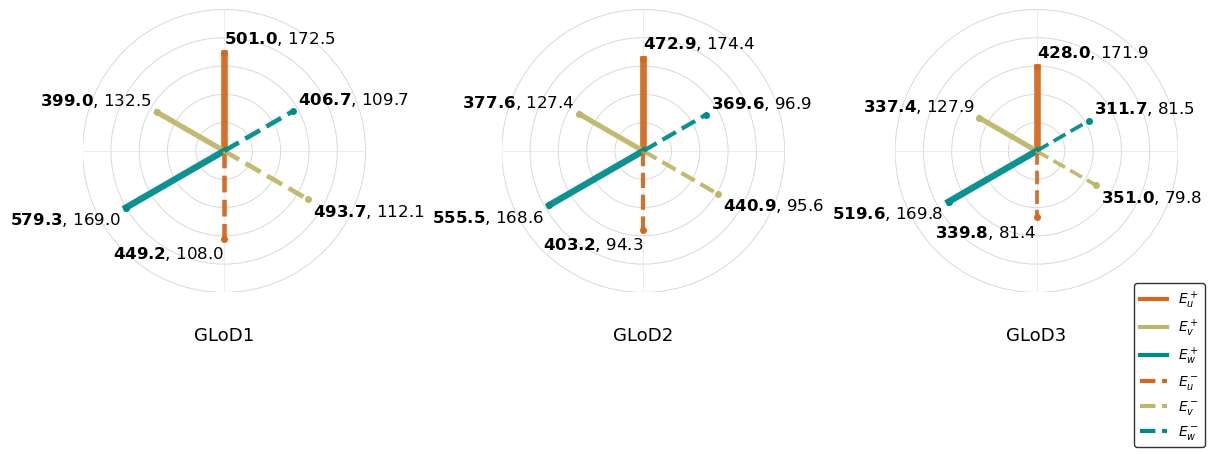

In [2]:
from matplotlib.lines import Line2D

labels = ["E_u_plus", "E_v_plus", "E_w_plus", "E_u_minus", "E_v_minus", "E_w_minus"]
angles = np.linspace(np.pi / 2, np.pi / 2 + 2 * np.pi, len(labels), endpoint=False)

pair_colors = {
    "u": "chocolate",
    "v": "darkkhaki",
    "w": "darkcyan",
}

line_styles = {
    "plus": "-",
    "minus": "--",
}

# Extract ground truth (LoD 4) values
eup_gt = res_4.cu.cubic_grid_array["E_u_plus"]
evp_gt = res_4.cu.cubic_grid_array["E_v_plus"]
ewp_gt = res_4.cu.cubic_grid_array["E_w_plus"]
eum_gt = res_4.cu.cubic_grid_array["E_u_minus"]
evm_gt = res_4.cu.cubic_grid_array["E_v_minus"]
ewm_gt = res_4.cu.cubic_grid_array["E_w_minus"]

# Compute medians/stds for each LoD
lod_stats = {}
all_meds = []
all_stds = []

for key, res__ in res_dict.items():
    eup_low = res__.cu.cubic_grid_array["E_u_plus"]
    evp_low = res__.cu.cubic_grid_array["E_v_plus"]
    ewp_low = res__.cu.cubic_grid_array["E_w_plus"]
    eum_low = res__.cu.cubic_grid_array["E_u_minus"]
    evm_low = res__.cu.cubic_grid_array["E_v_minus"]
    ewm_low = res__.cu.cubic_grid_array["E_w_minus"]

    nMAE_eup = np.mean(np.abs(eup_low - eup_gt), axis=1)
    nMAE_evp = np.mean(np.abs(evp_low - evp_gt), axis=1)
    nMAE_ewp = np.mean(np.abs(ewp_low - ewp_gt), axis=1)
    nMAE_eum = np.mean(np.abs(eum_low - eum_gt), axis=1)
    nMAE_evm = np.mean(np.abs(evm_low - evm_gt), axis=1)
    nMAE_ewm = np.mean(np.abs(ewm_low - ewm_gt), axis=1)

    vals = [nMAE_eup, nMAE_evp, nMAE_ewp, nMAE_eum, nMAE_evm, nMAE_ewm]
    medians = np.array([np.median(x) for x in vals])
    stds = np.array([np.std(x) for x in vals])

    lod_stats[key] = {"medians": medians, "stds": stds}
    all_meds.append(medians)
    all_stds.append(stds)

all_meds = np.concatenate(all_meds)
all_stds = np.concatenate(all_stds)
lim = 1.25 * all_meds.max()
max_std = all_stds.max() if all_stds.size else 1.0

fig, axes = plt.subplots(1, len(res_dict), figsize=(12, 6), constrained_layout=True)
if len(res_dict) == 1:
    axes = [axes]

for ax, (key, stats) in zip(axes, lod_stats.items()):
    meds = stats["medians"]
    stds = stats["stds"]

    # draw light grey concentric circles for scale reference
    radii = np.linspace(lim / 5.0, lim, 5)
    for r in radii:
        circ = plt.Circle((0, 0), r, edgecolor="0.85", facecolor="none", lw=0.7, zorder=0)
        ax.add_patch(circ)

    for lab, ang, med, std in zip(labels, angles, meds, stds):
        comp = lab.split("_")[1]
        sign = lab.split("_")[2]
        color = pair_colors[comp]
        ls = line_styles[sign]

        x = med * np.cos(ang)
        y = med * np.sin(ang)

        lw = 0.8 + 4.0 * (std / max_std)

        ax.plot([0, x], [0, y], color=color, lw=lw, linestyle=ls, alpha=0.95)
        ax.plot(x, y, marker="o", color=color, markersize=4)

        dx = 0.04 * lim * np.cos(ang)
        dy = 0.04 * lim * np.sin(ang)
        ax.text(
            x + dx,
            y + dy,
            f"$\\mathbf{{{med:.1f}}}$, " + rf"{std:.1f}",
            fontsize=12,
            ha="left" if np.cos(ang) >= 0 else "right",
            va="bottom" if np.sin(ang) >= 0 else "top",
        )

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.axhline(0, color="0.9", lw=0.5, zorder=0)
    ax.axvline(0, color="0.9", lw=0.5, zorder=0)
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

    ax.text(
        0.5, -0.12, key,
        transform=ax.transAxes,
        ha="center", va="top",
        fontsize=13
    )

legend_handles = [
    Line2D([0], [0], color=pair_colors["u"], lw=3, linestyle="-",  label=r"$E_u^+$"),
    Line2D([0], [0], color=pair_colors["v"], lw=3, linestyle="-",  label=r"$E_v^+$"),
    Line2D([0], [0], color=pair_colors["w"], lw=3, linestyle="-",  label=r"$E_w^+$"),
    Line2D([0], [0], color=pair_colors["u"], lw=3, linestyle="--", label=r"$E_u^-$"),
    Line2D([0], [0], color=pair_colors["v"], lw=3, linestyle="--", label=r"$E_v^-$"),
    Line2D([0], [0], color=pair_colors["w"], lw=3, linestyle="--", label=r"$E_w^-$"),
]

fig.legend(handles=legend_handles, loc="lower right", ncol=1, frameon=True, edgecolor="black")
fig.savefig("R2_nMAE_star_all_lods.pdf", bbox_inches="tight")
# save the pdf

plt.show()

Processing LoD 1


/home/nforouzandehsh/daylight_codes/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/daylight_codes/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)


shape of multiplier: 8761


/home/nforouzandehsh/daylight_codes/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/daylight_codes/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)


shape of multiplier: 4526


/home/nforouzandehsh/daylight_codes/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/daylight_codes/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)


shape of multiplier: 2078


/home/nforouzandehsh/daylight_codes/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/daylight_codes/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)


shape of multiplier: 2159
saved to sky_influence_DB_W01050_LoD_4_actual_cubic.csv.gz.pdf


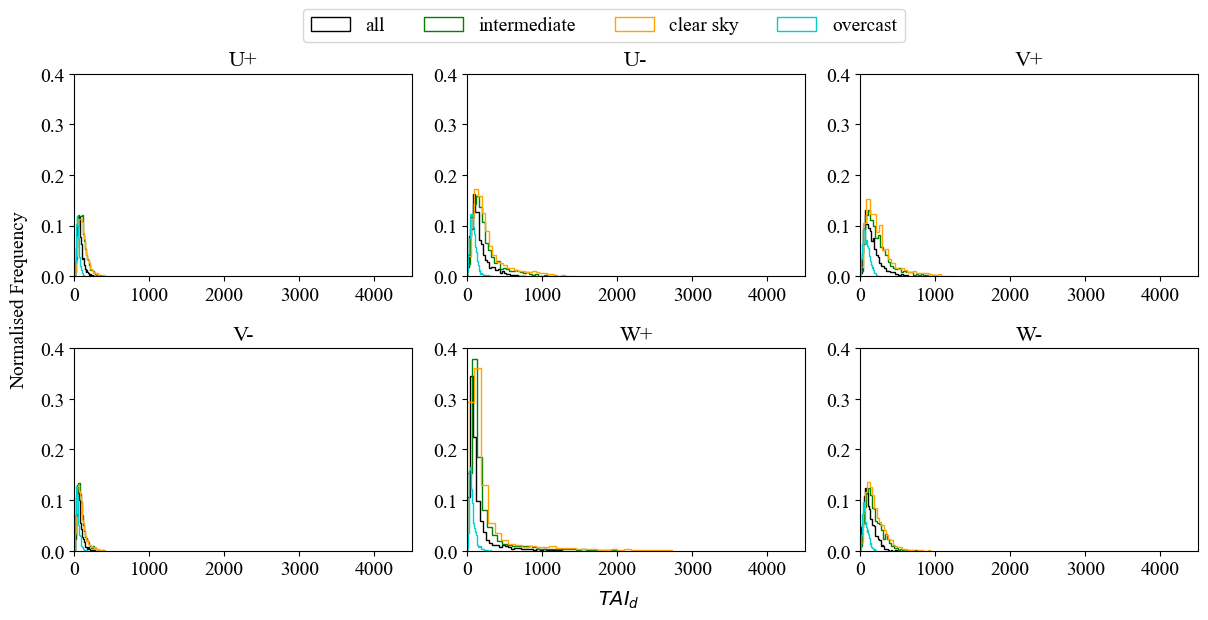

Processing LoD 2


/home/nforouzandehsh/daylight_codes/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/daylight_codes/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)


shape of multiplier: 8761


/home/nforouzandehsh/daylight_codes/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/daylight_codes/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)


shape of multiplier: 4526


/home/nforouzandehsh/daylight_codes/cuttle.py:245: RuntimeWarning: invalid value encountered in divide
  Diffuseness = 1 - (abs_E/Esr)/4
/home/nforouzandehsh/daylight_codes/cuttle.py:262: RuntimeWarning: invalid value encountered in divide
  abs_E_to_Esr = np.where((Esr != 0) & (~np.isnan(Esr)), abs_E / Esr, np.nan)


shape of multiplier: 2078


ParserError: Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.

In [ ]:
# sky type inflence
import sys
sys.path.append(r"/home/nforouzandehsh/daylight_codes/")
from postprocess import sky_influence

for LoD in [1, 2, 3, 4]:
    print(f"Processing LoD {LoD}")
    sky_influence(
        path_to_results=r"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_4_actual_cubic.csv.gz",
        # path_to_results=fr"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_{LoD}_actual_cubic.csv.gz",
        epwpath=r"/home/nforouzandehsh/RQ1/inputs/weather_files/NLD_ZH_Rotterdam.The.Hague.AP.063440_TMYx.epw",
        grid = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06/cubic_locations.txt",
        # grid = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10/points_cubic_location.txt",
        path_to_geometry_folder = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06"
        #path_to_geometry_folder = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10"
        )

In [2]:
# sky type inflence
import sys
sys.path.append(r"/home/nforouzandehsh/daylight_codes/")
from postprocess import sky_influence

for LoD in [3]:
    print(f"Processing LoD {LoD}")
    sky_influence(
        # path_to_results=fr"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_{LoD}_actual_cubic.csv.gz",
        path_to_results=fr"/scratch/nforouzandehsh/temp/RQ1/DB_550_LoD_{LoD}_actual_cubic.csv.gz",
        epwpath=r"/home/nforouzandehsh/RQ1/inputs/weather_files/NLD_ZH_Rotterdam.The.Hague.AP.063440_TMYx.epw",
        # grid = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06/cubic_locations.txt",
        grid = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10/points_cubic_location.txt",
        # path_to_geometry_folder = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06",
        path_to_geometry_folder = r"/home/nforouzandehsh/RQ1/inputs/WBG550/manual_surface_model/S10",
        x_lim_max= 4000)

Processing LoD 3


ValueError: The number of points in the grid file (2040) does not match the number of points in the result file (0).

In [ ]:
import pandas as pd
import numpy as np
import sys
sys.path.append(r"/home/nforouzandehsh/daylight_codes/")
from postprocess import *
epwpath=r"/home/nforouzandehsh/RQ1/inputs/weather_files/NLD_ZH_Rotterdam.The.Hague.AP.063440_TMYx.epw"

df = pd.read_csv(epwpath, skiprows=8, header=None)
df.columns = list(range(df.shape[1]))
cloud_cover = df[22].values

all_mask = np.ones(len(cloud_cover), dtype=bool)
overcast_mask = np.isin(cloud_cover, [8, 9, 10])
clear_sky = np.isin(cloud_cover, [0,1,2])
intermediate_mask = np.isin(cloud_cover, [3,4,5,6,7])

results = []

for lod in [1, 2, 3, 4]: # lod
    for sky in ['all', 'overcast', 'clear sky', 'intermediate']: #sky
        if sky == 'all':
            mask = np.insert(all_mask,0, True)
        elif sky == 'overcast':
            mask = np.insert(overcast_mask,0, True)
        elif sky == 'clear sky':
            mask = np.insert(clear_sky,0, True)
        elif sky == 'intermediate':
            mask = np.insert(intermediate_mask,0, True)

#         hp = head_pose(
#             results = fr"/scratch/nforouzandehsh/temp/RQ1/DB_W01050_LoD_2_actual_cubic.csv.gz",
#             grid = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06/cubic_locations.txt",
#             temporal_multiplier = mask,  # from your sky_influence masks
#             path_to_geometry_folder = r"/home/nforouzandehsh/RQ1/inputs/W01050/manual_surface_model/S06"
#         )
#         adapl = hp.all_directions_all_point_locations()
#         results.append({
#             'LoD': lod,
#             'Sky': sky,
#             'Room': 'WBG550',
#             'U+': np.mean(adapl['u_plus']),
#             'U-': np.mean(adapl['u_minus']),
#             'V+': np.mean(adapl['v_plus']),
#             'V-': np.mean(adapl['v_minus']),
#             'W+': np.mean(adapl['w_plus']),
#             'W-': np.mean(adapl['w_minus'])
#         })
# df = pd.DataFrame(results)